<img src=../figures/Brown_logo.svg width=50%>

# Data-Driven Design & Analyses of Structures & Materials (3dasm)

## Lecture 26

### Miguel A. Bessa | <a href = "mailto: miguel_bessa@brown.edu">miguel_bessa@brown.edu</a>  | Associate Professor

### Suryanarayanan M. S. | <a href = "mailto: s.manojsanu@tudelft.nl">s.manojsanu@tudelft.nl</a>  | PhD Candidate

# Outline for today's lecture
* Recap of previous lecture
* Zeroth-order optimizers
* Optimality criteria
* Gradient-based optimizers
    
**References:**
* J. R. R. Martins & Andrew Ning, Engineering Design Optimization, 2021 - Chapters 1 & 4
* For practical details of algorithms (Extra):
    * Nocedal, Jorge, and Stephen J. Wright. Numerical optimization. Springer Science & Business Media, 2006.
* For Adam, momentum & Adagrad
    * Ian Goodfellow and Yoshua Bengio and Aaron Courville. Deep Learning. MIT Press, 2016 - Chapter 8

## Recap & contextualization
<img align=right src="./figures/recap.png" width=40%>

**1. Unconstrained minimization**

**2. Convex functions look like bowls**
* Well behaved     
* Near a (strict) local minimum, every smooth function looks like a convex bowl!  

**3. Optimizer tradeoff**
* Exploration vs exploitation  
* Order of information (Taylor series expansion)

In [1]:
# Basic plotting tools needed in Python.
import matplotlib.pyplot as plt # import plotting tools to create figures
import numpy as np # import numpy to handle a lot of things!

%config InlineBackend.figure_format = "retina" # render higher resolution images in the notebook
plt.rcParams["figure.figsize"] = (8,4) # rescale figure size appropriately for slides

In [2]:
# @title Figure code: the FunctionPlot helper for the "walking as an optimizer" exercise
class FunctionPlot():
    """Simple class to manage plotting of a function.

    Plot the function, its first order model and its second order model.
    All of these can be plotted one by one interactively.
    """
    def __init__(self, bounds=50, convex=True):
        self.count = 0
        self.saved_x = []  # Saved every input received
        self.line = None
        self.bounds = bounds  # Bounds on the decision variable
        self.convex = convex

        self.random_coeff = np.random.choice([-25, -15, 10, 20])  # For the underlying function
        self.sine_coeff = 100
        self.sine_freq = 0.2
        self.show_canvas()

    def underlying_func(self, x):
        """True function.
        Sum of two functions:
        1. A quadratic function with a random coefficient
        The form is ax**2 - bx + c, where a is 1, b is random_coeff and c is 1.
        2. a*sine(b*x) 
        """
        if self.convex:
            return x**2 - self.random_coeff*x + 1
        else:
            return x**2 - self.random_coeff*x + 1 + self.sine_coeff*np.sin(self.sine_freq*x)

    def gradient(self, x):
        """The gradient of the underlying function."""
        if self.convex:
            return 2*x - self.random_coeff
        else:
            return 2*x - self.random_coeff + self.sine_coeff*self.sine_freq*np.cos(self.sine_freq*x)

    def hessian(self, x):
        if self.convex:
            return 2
        else:
            return 2 - self.sine_coeff*self.sine_freq**2*np.sin(self.sine_freq*x)

    def first_order_model(self, x, x0):
        """The first order model of the underlying function."""
        return self.underlying_func(x0) + self.gradient(x0)*(x - x0)

    def second_order_model(self, x, x0):
        """The second order model of the underlying function."""
        return self.underlying_func(x0) + self.gradient(x0)*(x - x0) + 0.5*self.hessian(x0)*(x - x0)**2

    def show_canvas(self):
        """Shows the figure on which to plot along with the bounds."""
        fig, ax = plt.subplots(1, 1, figsize=(10, 5))
        ax.set_xlabel('x')
        ax.set_ylabel('y = f(x)')
        ax.set_xlim(-self.bounds, self.bounds)
        ax.axvline(x=-self.bounds+3, color='gray')  # To show the limit
        ax.axvline(x=self.bounds-3, color='gray')
        self.fig = fig
        self.ax = ax

    def plot(self, x_value, with_first_order=False, with_second_order=False):
        """Plots the function, its first order model or its second order model."""
        self.count += 1
        self.saved_x.append(x_value)

        self.ax.plot(self.saved_x,
                         [self.underlying_func(x) for x in self.saved_x], 'ko')

        if with_first_order:
            self._plot_first_order_model()
        elif with_second_order:
            self._plot_second_order_model()
        else:
            pass

#         self.ax.legend()
        plt.show()

    def _plot_first_order_model(self):
        if self.line is not None:
            self.line.pop(0).remove()
        x = np.linspace(-self.bounds, self.bounds, 100)
        y = self.first_order_model(x, self.saved_x[-1])
        self.line = self.ax.plot(x, y, '--', color='purple', label='First-order model')

    def _plot_second_order_model(self):
        if self.line is not None:
            self.line.pop(0).remove()
        x = np.linspace(-self.bounds, self.bounds, 100)
        y = self.second_order_model(x, self.saved_x[-1])
        self.line = self.ax.plot(x, y, '--', color='purple', label='Second-order model')

    def plot_minimum(self):
        """Shows the minimum of the function."""
        if self.convex:
            min_x = self.random_coeff / 2
            min_y = self.underlying_func(min_x)
        else:
            x = np.linspace(-self.bounds, self.bounds, 200)
            yvals = self.underlying_func(x)
            min_x = x[np.argmin(yvals)]
            min_y = np.min(yvals)            
        
        self.ax.plot(min_x, min_y, '*', markersize=20, color='k', label='Minimum')

    def plot_func(self):
        x = np.linspace(-self.bounds, self.bounds, 100)
        y = self.underlying_func(x)
        self.ax.plot(x, y, "k:",label='True function')


# Exercise: walking as an optimizer

* Understand different optimizers
    * How they perceive the objective function landscape
* Black dots - Evaluations of the underlying function
* Gray lines - bounds
* Black star - Minimum

#### We will see how important information is!


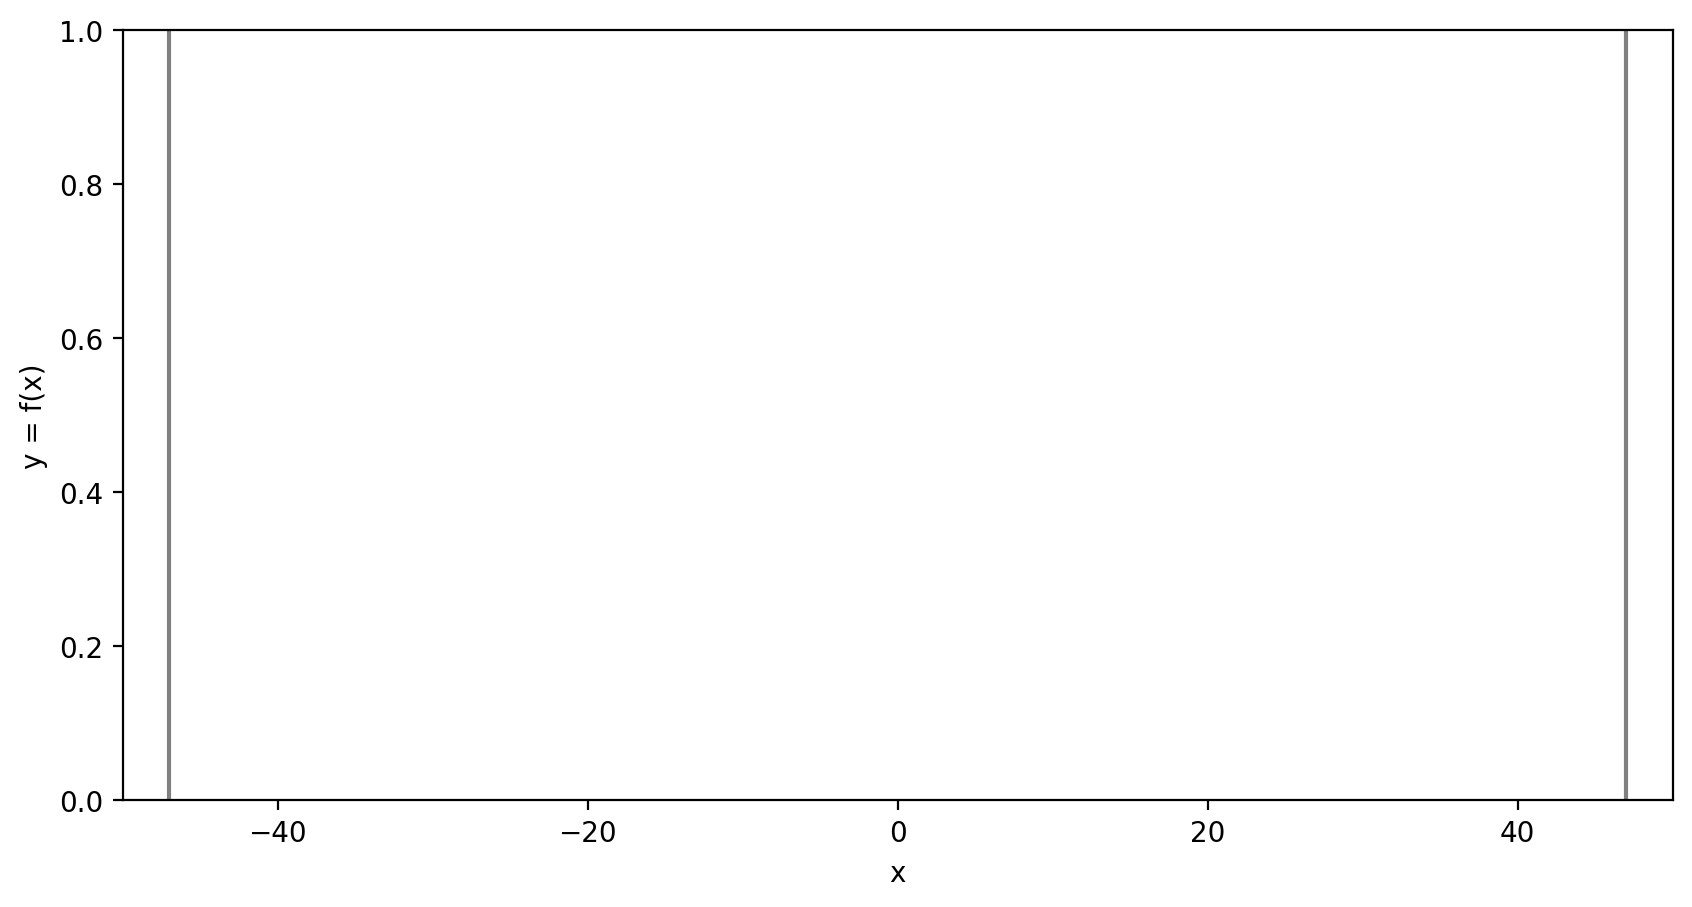

In [3]:
# Create the object separately in a cell
plotter = FunctionPlot(convex=False, bounds=50)

# Zeroth-order optimizers
* Black-box / derivative-free optimizers
    * Only access function's outputs
* Used extensively for hyperparameter optimization
    * Decision variables are discrete (or mixed)
    * Discontinuous functions
        * Gradient and Hessian are not defined (or not used or not accessible)

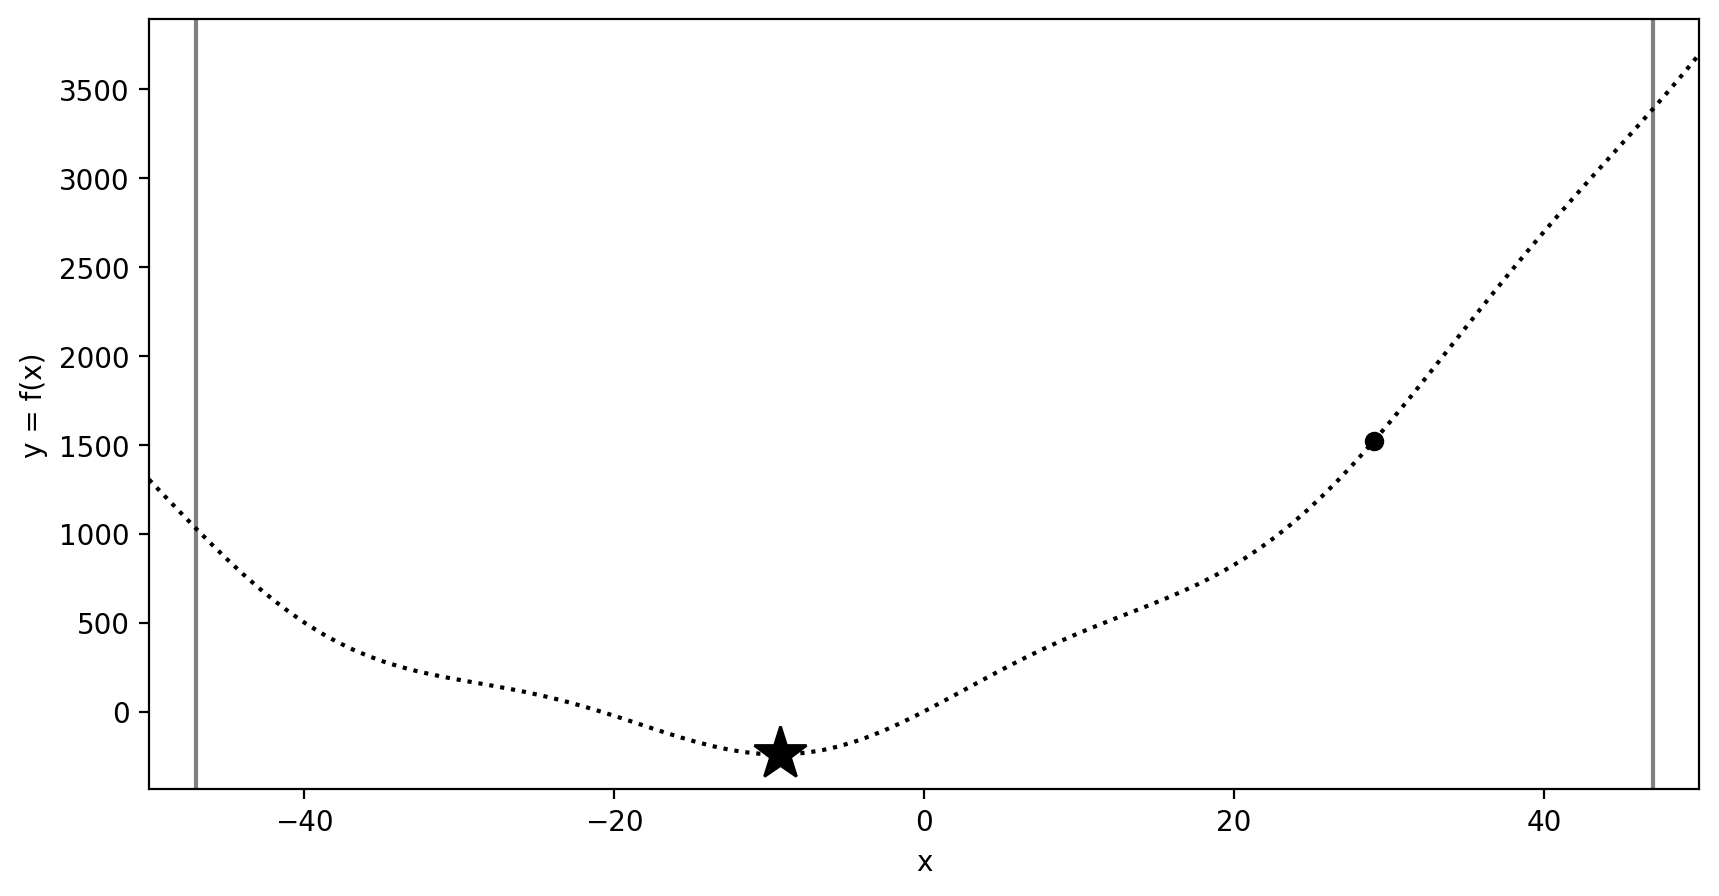

In [4]:
x = 29  # Make guesses!
plotter.plot(x)
plotter.plot_minimum()
plotter.plot_func()
plotter.fig

### Issues with Zeroth-order methods
* Not very efficient.
    * The number of function evaluations increases exponentially with dimensionality.
        * `Curse of dimensionality`.

* Usually do not know when to stop!
    * **Cannot identify minima**

# How to know a minimum if we see one

* Minima are defined as points better than their neighborhood
* To identify minima
    * "Look" around a point
* We need a local model of the objective function

**Local model using Taylor series**


$$ f(\mathbf{x} + \alpha \mathbf{p})|_{\mathbf{x}=\mathbf{x}_0} \approx f(\mathbf{x}_0) + \alpha \nabla f(\mathbf{x}_0)^T \mathbf{p} + \frac{1} {2}\alpha^2 \mathbf{p}^T   \mathbf{H}(\mathbf{x}_0)   \mathbf{p}$$

$$ \text{Gradient: } \nabla f(\mathbf{x}) = \Big[\frac{\partial f}{ \partial x_1}, \frac{\partial f}{ \partial x_2} ..., \frac{\partial f}{ \partial x_{D_x}} \Big]^T$$


$$ \text{Hessian: } H(\mathbf{x}) = \begin{bmatrix} \frac{\partial^2 f}{\partial x_1^2} & \cdots & \frac{\partial^2 f}{\partial x_1 \partial x_{D_x}} \\ \vdots &  \ddots & \vdots \\ \frac{\partial^2 f}{\partial x_{D_x} \partial x_1} & \cdots & \frac{\partial^2 f}{\partial x_{D_x}^2} \end{bmatrix} $$

**Need gradients and/or Hessian information**

## Optimality criteria

* Mathematical conditions to identify minima from other points!
* In practice,
    * Used internally by gradient-based optimizers
        * to find minima and to stop.
    * In constrained optimization
        * Optimality is checked with KKT (Karush-Kuhn-Tucker) conditions.

### First-order condition
* **At a local minimum, gradient vanishes.**
    * $\nabla f(\mathbf{x}^*) = \mathbf{0}$
<img align=right src="./figures/1d_optimality.png" width=50%>
* In one-dimension:
    * Slope = 0 at every minimum (High school calculus!)
* In multi-dimensions:
    * Gradient = collection of slopes
    * **Gradient** = **0**: Slope in every direction is zero
* If the gradient is non-zero
    * We can travel **opposite** to the gradient to reduce the function further.
    * (Remember that the gradient points in the ascent direction!)


🚨 **Gradient can be zero at other places too** 🚨
* Stationary points
    * Local maxima
    * Saddle points!
    

* So how do we check ?

We can look at the Hessian...

### Second-order condition

* Hessian is the **curvature matrix**
    * Eigenvalues are curvatures along different directions
* Local minima
    * If Hessian = positive definite (all eigenvalues are > 0)
    * In one-dimension: $H(x^*) > 0$
* Local maxima
    * If Hessian = negative definite (all eigenvalues < 0)
* Saddle point
    * If Hessian has positive and negative eigenvalues
* If semi-definite (some/all eigenvalues are zero), then we are not sure!

<img src="./figures/hessian_stationary_points.png" width=60%>

## Gradient-based optimizers

<img align=center src="./figures/opt_spectrum.png" width=50%>

* Spectrum: from first order to second order
    * Based on Taylor series local model

**Common steps:**

**1. They need a guess to start - Initialization**

**2. Update rule to make better guesses**

$\mathbf{x}_{k+1} = \mathbf{x}_k + \alpha \mathbf{p}$

* $\mathbf{p}$ is a **search direction**
    * Which direction to move ?
    * $\mathbf{p}$ depends on $\nabla f$
* $\alpha$ is a **step size** (in ML, sometimes called learning rate)
    * How much to move along $\mathbf{p}$ 
    * Usually it is a scalar
    
**3. Stopping criteria**
* E.g. $||\nabla f(\mathbf{x})|| \leq \epsilon $, where $\epsilon$ is some tolerance

## Gradient descent (GD)

* Simplest gradient-based optimizer
    * Utilize only gradients
    * Pure first-order

* Search direction , $\mathbf{p} = - \nabla f$
    * Steepest descent!
    * We are decreasing the function's value most rapidly.

* Step size, $\alpha$ = scalar
    * Same for all directions

* **Stochastic gradient descent (SGD)**
    * Common ML optimizer for large datasets
    * Gradient is estimated using **minibatches** (subsets of the training data; more on this later)
    * Full batch, i.e. when using full training data, SGD = GD

### Choosing step size (a.k.a. learning rate) matters

<img align=right src="./figures/lr.png" width=40%>

* Most important hyper-parameter
    * For most gradient-based optimizers
    * step size = learning rate
* Too small, slow convergence
    * Less exploration
    * "Bad" local minimum
* Too large, can diverge
    * Oscillations
    
Common strategy in ML:
* Use **learning rate schedule**, instead of a constant learning rate
    * E.g. decrease learning rate slowly at each increment $t$:
    
$$\mathbf{x}_{t+1} = \mathbf{x}_t + \alpha_t \mathbf{p}$$

**Question**: Can you try to anticipate when **Stochastic Gradient Descent** (SGD) is used instead of **Gradient Descent** (GD)?

1. For very large datasets and for models with many variables, because GD needs the gradient over the **entire** training dataset at every step, which is expensive to compute (and to fit in memory)

2. Also, because SGD does not use the complete gradient for the entire training dataset to update the model parameters, this causes "noise" and that can act as regularization!

We will discuss this in more detail when learning about artificial neural networks.

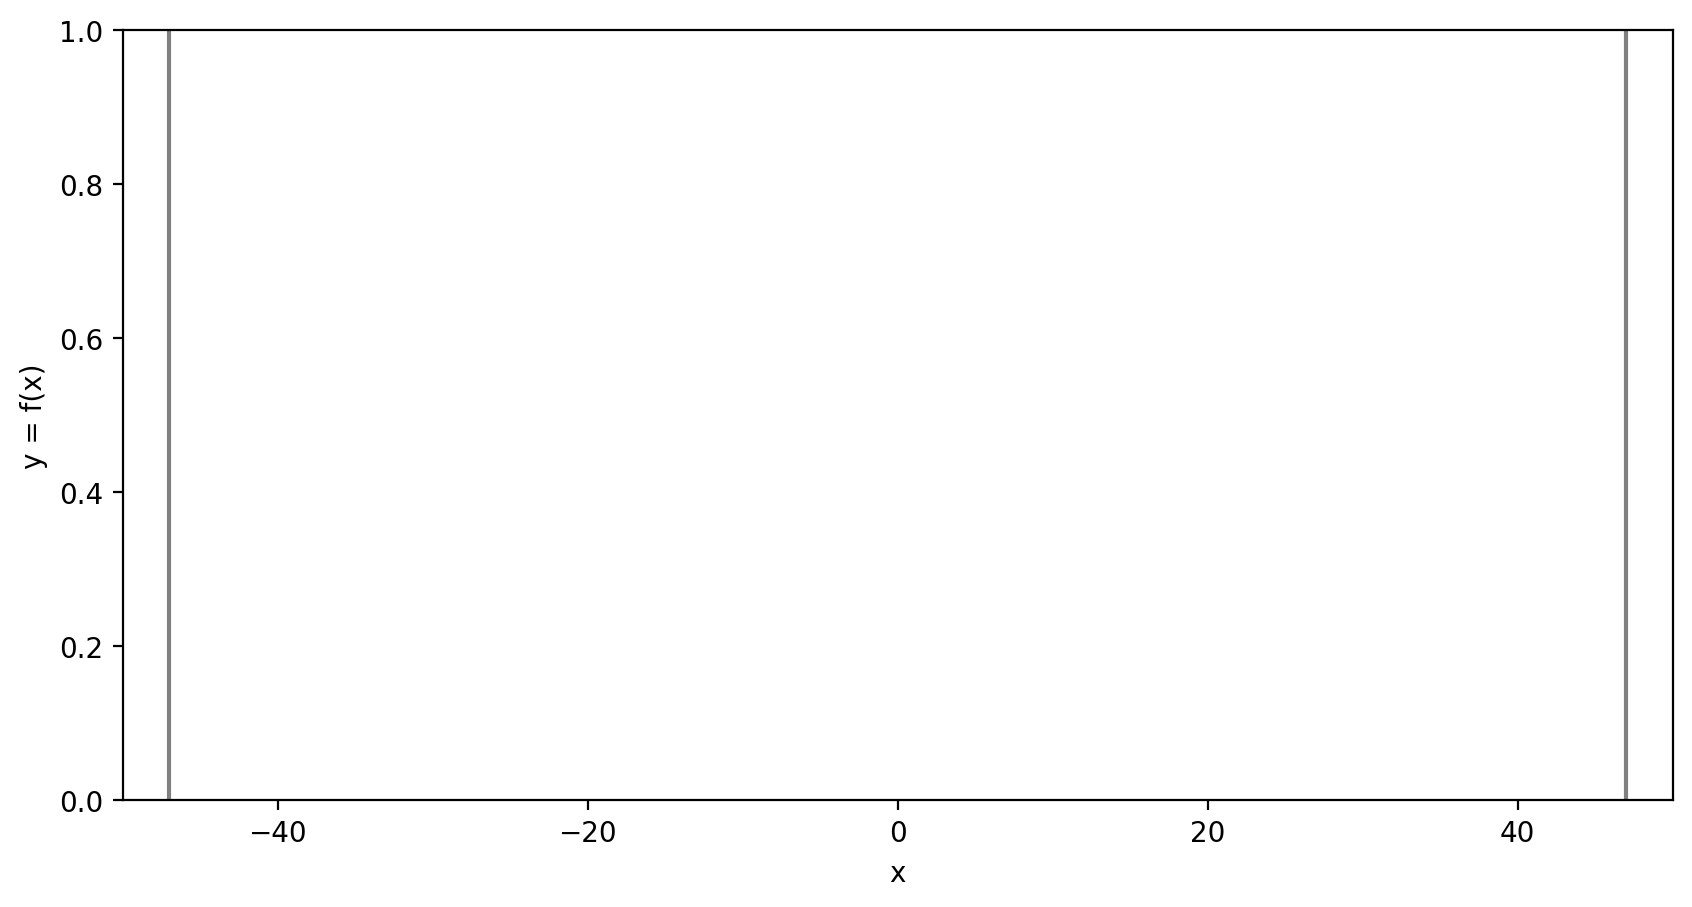

In [5]:
plotter = FunctionPlot(convex=True, bounds=50)

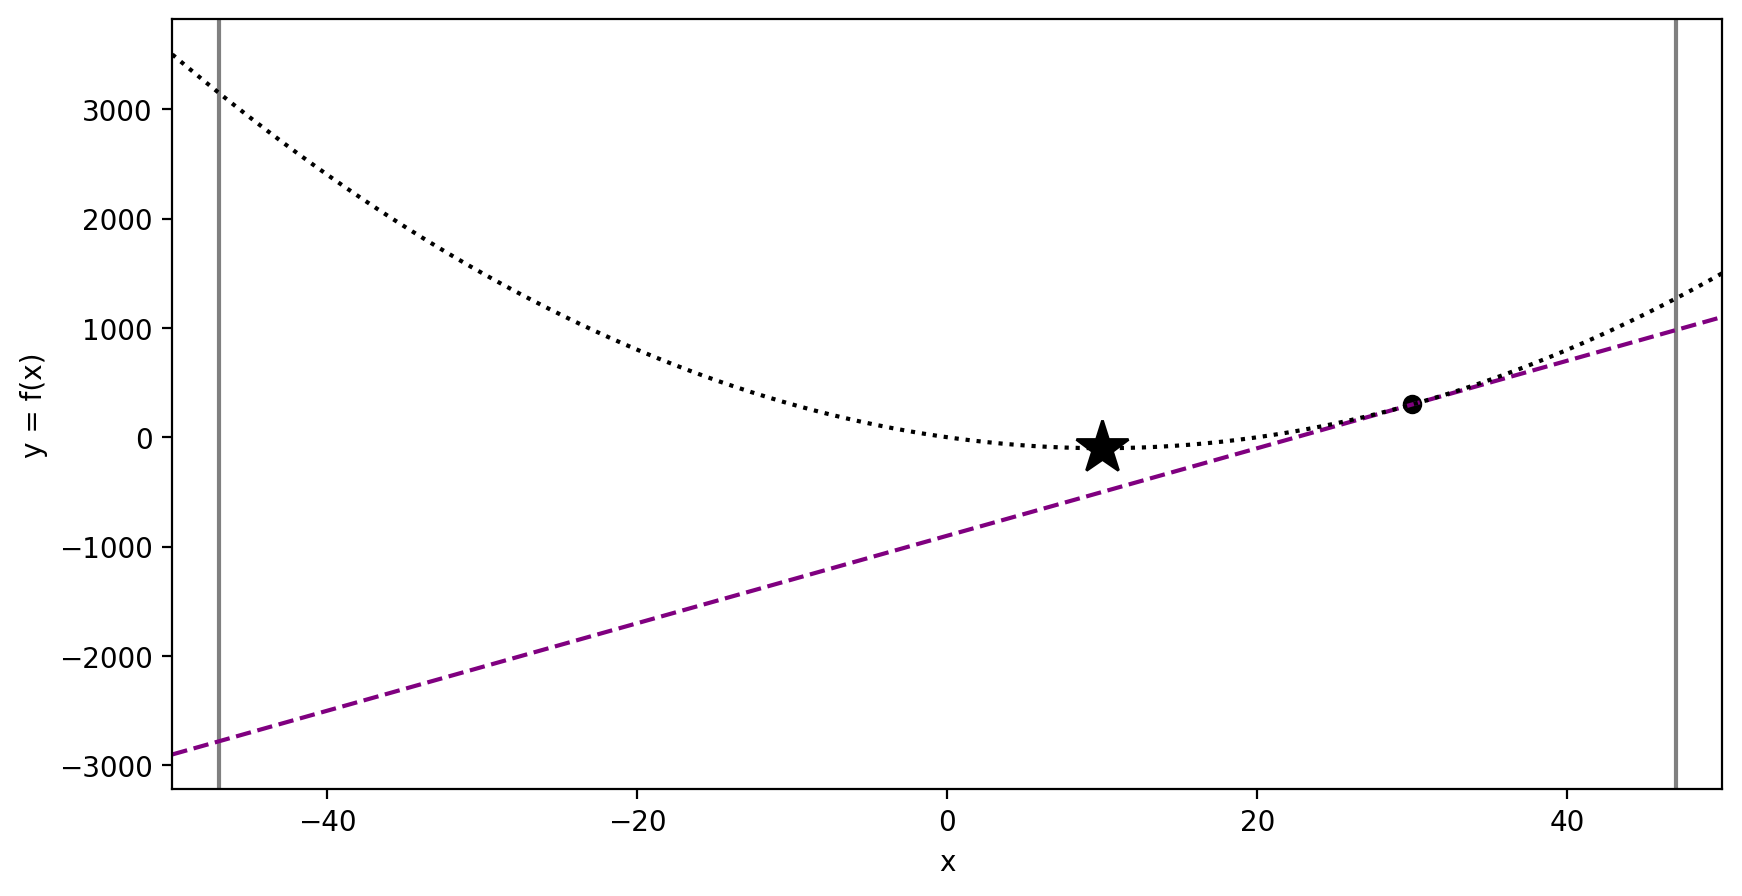

In [7]:
x = 30
plotter.plot(x, with_first_order=True)
plotter.plot_minimum()
plotter.plot_func()
plotter.fig

# Summary

* Zeroth-order optimizers
    * Common choice for black-box functions
    * Curse of dimensionality
* Optimality criteria
    * Gradient and Hessian to identify minima
* Gradient-based optimizers
    * General format is to have a search direction and step size (a.k.a. learning rate)
* GD and SGD
    * Simple but can oscillate

### See you next class

Have fun!